### Imports

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import toml

DATASETS_ROOT = "./datasets"

### Funções

In [2]:
def load_dataset_reference(datasets_root: str, dataset_name: str, reference_name: str):
    """
    Carrega o info.toml e os dataset de referência especificado
    de um dataset em formato pandas DataFrame.

    Returns:
        reference_df.
    """
    dataset_dir = Path(datasets_root) / dataset_name
    info = toml.load(dataset_dir / "info.toml")
    use_cols = info.get("split-info", {}).get("use_col")

    original_df = pd.read_csv(dataset_dir / f"{dataset_name}.csv")
    if use_cols:
        original_df = original_df[use_cols]

    reference_df = pd.read_csv(dataset_dir / "reference" / f"{reference_name}.csv")

    return reference_df

In [3]:
def load_datasets(datasets_root: str, dataset_name: str):
    """
    Carrega o info.toml e os datasets (original, treino, teste e referência)
    de um dataset específico em formato pandas DataFrame.

    Returns:
        Tuple contendo (original_df, train_df, test_df, reference_df).
    """
    dataset_dir = Path(datasets_root) / dataset_name
    info = toml.load(dataset_dir / "info.toml")
    use_cols = info.get("split-info", {}).get("use_col")

    original_df = pd.read_csv(dataset_dir / f"{dataset_name}.csv")
    if use_cols:
        original_df = original_df[use_cols]

    train_df = pd.read_csv(dataset_dir / "real" / f"{dataset_name}_train.csv")
    test_df = pd.read_csv(dataset_dir / "real" / f"{dataset_name}_test.csv")
    reference_df = pd.read_csv(dataset_dir / "reference" / f"{dataset_name}_reference.csv")

    return original_df, train_df, test_df, reference_df


def get_label_column(datasets_root: str, dataset_name: str) -> str:
    """Retorna o nome da coluna de label definido no info.toml do dataset."""
    info = toml.load(Path(datasets_root) / dataset_name / "info.toml")
    return info["columns"]["label"]

In [4]:
def plot_label_distribution(labels: pd.Series, title: str | None = None):
    """Plota a distribuição de classes de um dataset usando seaborn.histplot."""
    labels_clean = labels.dropna().sort_values().astype(str)

    fig, ax = plt.subplots(figsize=(5, 4))
    sns.histplot(x=labels_clean, discrete=True, shrink=0.8, ax=ax)

    total = len(labels_clean)
    if total > 0:
        for container in ax.containers:
            bar_labels = [
                f"{int(b.get_height())} ({b.get_height() / total:.1%})"
                for b in container
            ]
            ax.bar_label(container, labels=bar_labels, padding=3, fontsize=9)

    _, ymax = ax.get_ylim()
    ax.set_ylim(0, ymax * 1.15)
    ax.set_xlabel(labels.name or "Label")
    ax.set_ylabel("Contagem")
    if title:
        ax.set_title(title)
    ax.grid(axis="y", linestyle="--", alpha=0.5)
    ax.set_axisbelow(True)

    plt.tight_layout()
    plt.show()

### Alabama Income

In [5]:
alabama_orig, alabama_train, alabama_test, alabama_ref = load_datasets(DATASETS_ROOT, "alabama_income")
alabama_label = get_label_column(DATASETS_ROOT, "alabama_income")

georgia_orig = load_dataset_reference(DATASETS_ROOT, "alabama_income", "georgia_income")
colorado_orig = load_dataset_reference(DATASETS_ROOT, "alabama_income", "colorado_income")

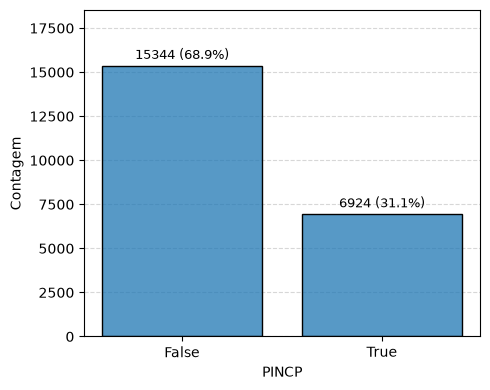

In [6]:
plot_label_distribution(alabama_orig[alabama_label])

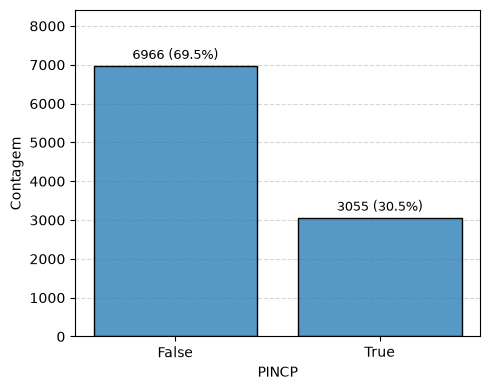

In [7]:
plot_label_distribution(alabama_train[alabama_label])

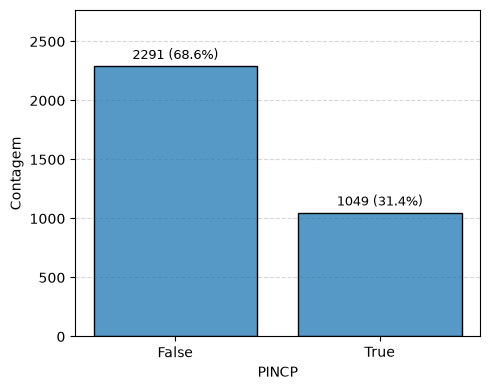

In [8]:
plot_label_distribution(alabama_test[alabama_label])

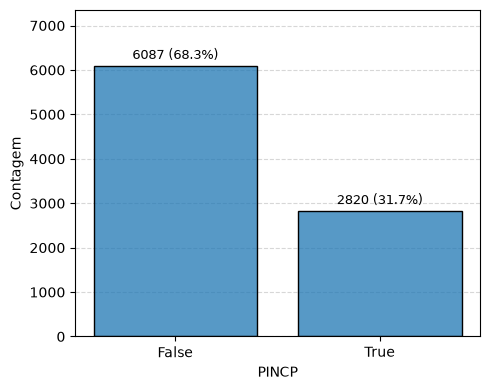

In [9]:
plot_label_distribution(alabama_ref[alabama_label])

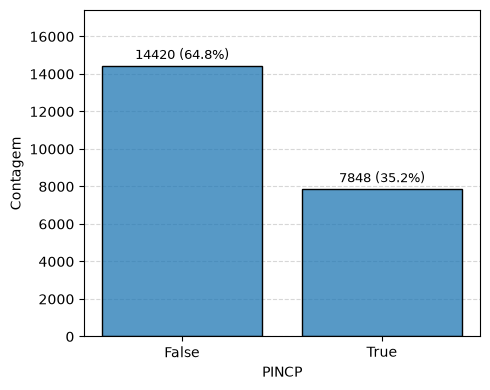

In [10]:
plot_label_distribution(georgia_orig[alabama_label])

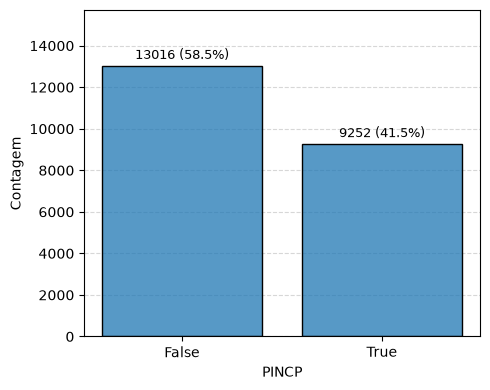

In [11]:
plot_label_distribution(colorado_orig[alabama_label])

### Cidds

In [12]:
cidds_orig, cidds_train, cidds_test, cidds_ref = load_datasets(DATASETS_ROOT, "cidds")
cidds_label = get_label_column(DATASETS_ROOT, "cidds")

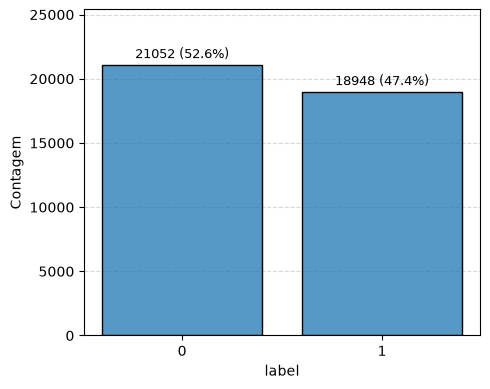

In [13]:
plot_label_distribution(cidds_orig[cidds_label])

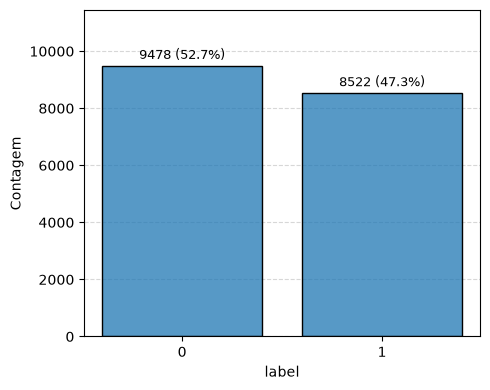

In [14]:
plot_label_distribution(cidds_train[cidds_label])

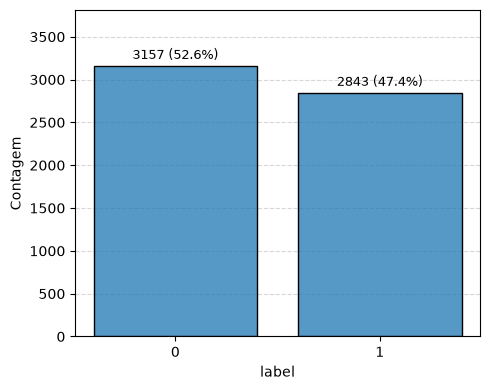

In [15]:
plot_label_distribution(cidds_test[cidds_label])

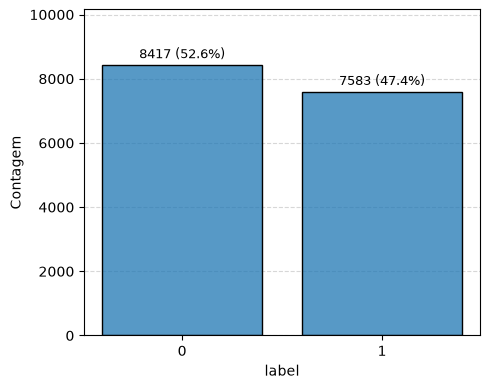

In [16]:
plot_label_distribution(cidds_ref[cidds_label])

### Breast Cancer

In [17]:
bc_orig, bc_train, bc_test, bc_ref = load_datasets(DATASETS_ROOT, "breast_cancer")
bc_label = get_label_column(DATASETS_ROOT, "breast_cancer")

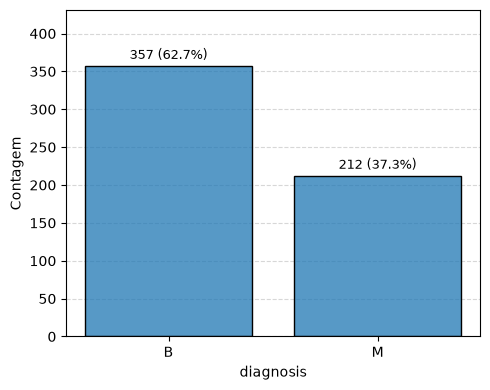

In [18]:
plot_label_distribution(bc_orig[bc_label])

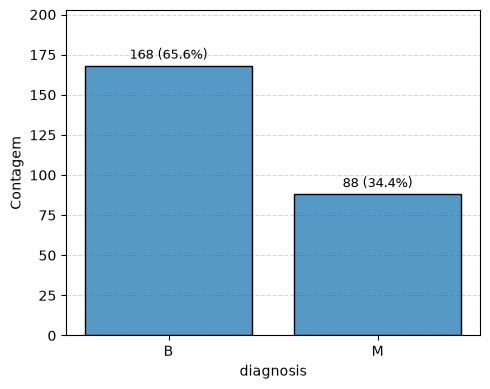

In [19]:
plot_label_distribution(bc_train[bc_label])

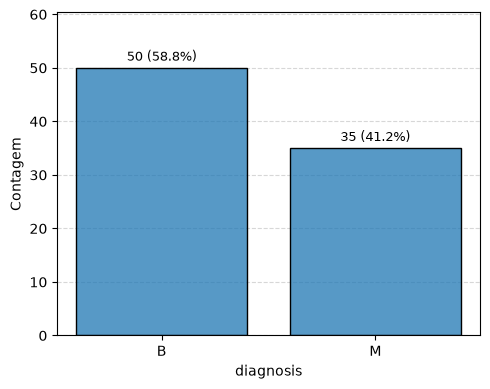

In [20]:
plot_label_distribution(bc_test[bc_label])

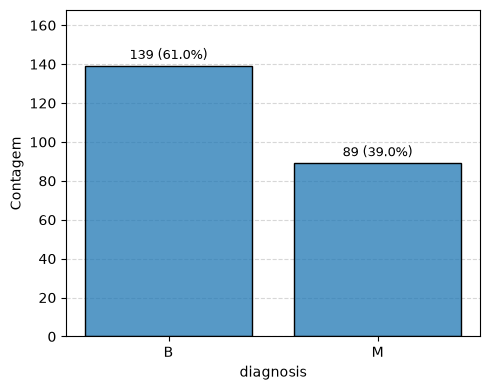

In [21]:
plot_label_distribution(bc_ref[bc_label])

### Default Credit

In [22]:
dc_orig, dc_train, dc_test, dc_ref = load_datasets(DATASETS_ROOT, "default_credit")
dc_label = get_label_column(DATASETS_ROOT, "default_credit")

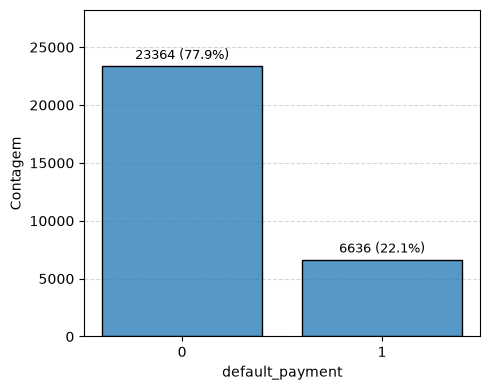

In [23]:
plot_label_distribution(dc_orig[dc_label])

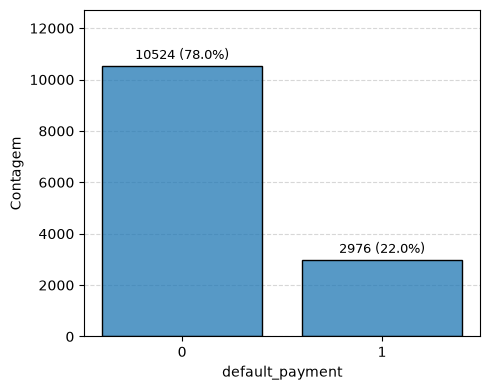

In [24]:
plot_label_distribution(dc_train[dc_label])

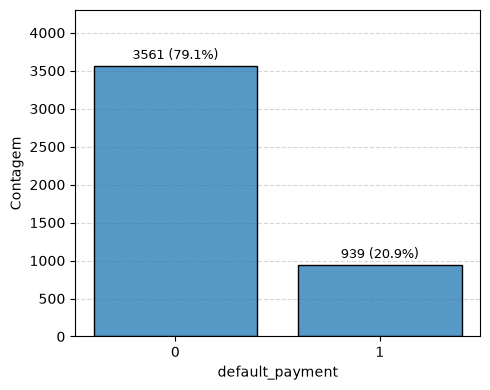

In [25]:
plot_label_distribution(dc_test[dc_label])

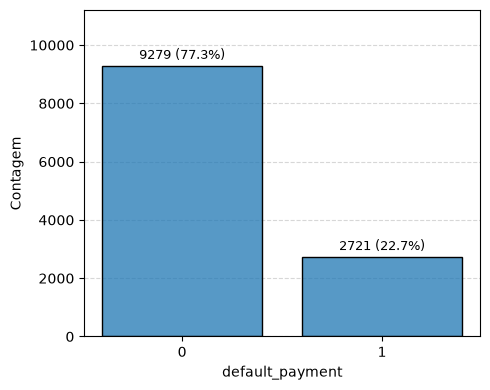

In [26]:
plot_label_distribution(dc_ref[dc_label])